# Distribution of the Topic Relevance Score, Overall and by Sector

| Item | Description |
|---|---|
| Goal | Two figures for the topic relevance score of T3.4.1. Figure 1 is the histogram of the firm scores over all sample firms. Figure 2 overlays the kernel density of the same scores for the information, manufacturing, and mining sectors, so the reader sees which sector sits to the right or to the left. |
| Input | `firm_relevance.parquet` from T3.4.1 in the T3.4 Processed folder, which carries each firm's NAICS sector. |
| Output | Under `R - Results/figures/...`: `fig_distribution_policy_summary_firm_summary_cosine_all_firms` and `fig_distribution_policy_summary_firm_summary_cosine_information_manufacturing_mining_kde`, each as PNG, SVG, and PDF. |
| Sample | The all-years sample, 1,058 firms; `SAMPLE` switches to the three-year sample. |
| Style | S3: 9 by 6 inches, Times, 0.5 cm margins, no text inside the plot, title and notes in Markdown below the image. Figure 1 has one series in GREY and no legend; Figure 2 has one palette color per sector and a legend below the X-title. Axis titles and legend entries are in title case, as the proposal's figures are. |
| Run | Run 2026-10-31. Figure 1 is Figure S5 of the proposal. |


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde


## Step 2. Define file locations, the sample, the sectors, and the wording

The titles, axis titles, and legend entries are built from two phrases that name the texts compared, so every figure says the same thing in the same words.


In [2]:
PROJECT_FOLDER = Path.cwd().resolve().parents[2]  # <pipeline>/<section>/<subfolder>/ sits three levels below the clone
SCRATCH_FOLDER = Path("/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis")  # the one line to change on another machine
NOTEBOOK_SUBFOLDER = Path("T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure/T3.4 - Topic Relevance - Score and Figures")
NOTEBOOK_NAME = "T3.4.2 - Figure - Distribution Overall and by Sector"  # the notebook filename without .ipynb
RAW_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Raw"
INTERIM_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Interim"
PROCESSED_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Processed"
SCORES_FILE = PROCESSED_FOLDER / "firm_relevance.parquet"

SAMPLE = "all_years"  # the main sample; "three_years" for the three-year figures
N_BINS = 30
FOCUS_SECTORS = ["Information", "Manufacturing", "Mining, quarrying, and oil and gas extraction"]  # Figure 2, in legend order
SECTOR_LEGEND = {"Information": "Information Sector (NAICS 51)", "Manufacturing": "Manufacturing Sector (NAICS 31 to 33)",
                 "Mining, quarrying, and oil and gas extraction": "Mining, Quarrying, and Oil and Gas Extraction Sector (NAICS 21)"}
FIRM_SUMMARY_TITLE = "a Firm-Level Summary of 10-K Item 1s"
POLICY_SUMMARY_TITLE = "the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation"
SCORE_TITLE = f"Cosine Similarity Between {FIRM_SUMMARY_TITLE} and {POLICY_SUMMARY_TITLE}"
SCORE_WORDS = ("the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's "
               "yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the "
               "language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. "
               "A higher score means that the firm's business description is closer to the policy summary")
SAMPLE_WORDS = {"three_years": "the three-year sample (fiscal years 2010, 2015, and 2020)", "all_years": "the all-years sample (every fiscal year a firm filed, 1999 to 2025)"}
SOURCE = "10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations"
FIGURE_TITLES = {1: f"Distribution of {SCORE_TITLE}", 2: f"Kernel Density of {SCORE_TITLE} for Firms in the Information, Manufacturing, and Mining Sectors"}
X_TITLE = f"Cosine Similarity Between {FIRM_SUMMARY_TITLE}\nand {POLICY_SUMMARY_TITLE}"  # the title's words on two lines
Y_TITLES = {1: "Number of Firms in the Bin", 2: "Kernel Density of Firms Within Each Sector\n(Area Under Each Curve Equals One)"}
FIGURE_NAMES = {1: "fig_distribution_policy_summary_firm_summary_cosine_all_firms", 2: "fig_distribution_policy_summary_firm_summary_cosine_information_manufacturing_mining_kde"}
FIGURE_FOLDER = PROJECT_FOLDER / "R - Results/figures" / NOTEBOOK_SUBFOLDER / NOTEBOOK_NAME
TABLE_FOLDER = PROJECT_FOLDER / "R - Results/tables" / NOTEBOOK_SUBFOLDER / NOTEBOOK_NAME
MODEL_CACHE = SCRATCH_FOLDER / "cache" / "huggingface"
ENV_FILE = PROJECT_FOLDER / "T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure" / ".env"
for folder in (FIGURE_FOLDER,):
    folder.mkdir(parents=True, exist_ok=True)


## Step 3. Apply the figure style

The S3 settings and the layout helpers: margins measured after drawing, the legend below the X-title, and three export formats.


In [3]:
# Colors from the Figure Style Guide
BLACK = "#000000"
DODGER_BLUE = "#1E90FF"
SLATE_GREY = "#708090"
CYAN = "#00ACC1"
GREY = "#A6A6A8"

# Font and background
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True

# Horizontal background lines only
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5

# All text and axis lines in BLACK
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK

FIGURE_WIDTH, FIGURE_HEIGHT = 9, 6
MARGIN_INCHES = 0.5 / 2.54  # 0.5 cm between each edge of the image and the nearest element
ZERO_LINE_WIDTH = 0.8 / 3
EXPORT_DPI = 300
LINE_WIDTH = 1.6
SECTOR_COLORS = {"Information": DODGER_BLUE, "Manufacturing": SLATE_GREY, "Mining, quarrying, and oil and gas extraction": CYAN}


def fit_margins(figure, axis):
    """Move the axes so the Y-title starts 0.5 cm from the left edge, the X-title ends 0.5 cm above the bottom edge, and nothing crosses the right or top margin."""
    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    margin = MARGIN_INCHES * figure.dpi
    left_shift = (margin - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
    figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
    figure.canvas.draw()
    bottom_shift = (margin - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
    figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
    figure.canvas.draw()
    box = axis.get_tightbbox(renderer)
    right_over = box.x1 - (figure.bbox.width - margin)
    top_over = box.y1 - (figure.bbox.height - margin)
    if right_over > 0 or top_over > 0:
        figure.subplots_adjust(right=figure.subplotpars.right - max(right_over, 0) / figure.bbox.width,
                               top=figure.subplotpars.top - max(top_over, 0) / figure.bbox.height)
        figure.canvas.draw()
    return renderer


def legend_below(figure, axis, handles, labels, ncol=1, fontsize=10):
    """Place the legend with its top 0.5 cm below the X-title and its bottom 0.5 cm above the bottom edge; the bottom margin grows to make room."""
    renderer = fit_margins(figure, axis)
    margin = MARGIN_INCHES * figure.dpi
    axis_box = axis.get_window_extent(renderer)
    center = (axis_box.x0 + axis_box.x1) / 2 / figure.bbox.width
    x_title = axis.xaxis.label.get_window_extent(renderer)
    legend = figure.legend(handles, labels, loc="upper center", bbox_to_anchor=(center, (x_title.y0 - margin) / figure.bbox.height),
                           bbox_transform=figure.transFigure, ncol=ncol, frameon=False, handlelength=1.6, fontsize=fontsize)
    figure.canvas.draw()
    bottom_shift = (margin - legend.get_window_extent(renderer).y0) / figure.bbox.height
    figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
    figure.canvas.draw()
    x_title = axis.xaxis.label.get_window_extent(renderer)
    legend.set_bbox_to_anchor((center, (x_title.y0 - margin) / figure.bbox.height), transform=figure.transFigure)
    figure.canvas.draw()
    return legend


def save_figure(figure, stem):
    """Export PNG, SVG, and PDF into the notebook's figure folder."""
    FIGURE_FOLDER.mkdir(parents=True, exist_ok=True)
    for extension in ("png", "svg", "pdf"):
        figure.savefig(FIGURE_FOLDER / f"{stem}.{extension}", dpi=EXPORT_DPI if extension == "png" else None)
    plt.close(figure)
    print(f"saved {stem}.png/.svg/.pdf")


def show_figure(number, title, stem, notes, source):
    """Title, image, Notes, and Source, in that order, as Markdown outside the image."""
    display(Markdown(f"**Figure {number}. {title}**"))
    display(Image(filename=str(FIGURE_FOLDER / f"{stem}.png"), width=900))
    display(Markdown(f"*Notes*: {notes}"))
    display(Markdown(f"*Source*: {source}."))


## Step 4. Load the scores

The chosen sample only; every focus sector must exist in it. Both figures share the X range of the sample.


In [4]:
scores = pd.read_parquet(SCORES_FILE)
scores = scores.loc[scores["sample"].eq(SAMPLE)].reset_index(drop=True)
assert scores["score"].notna().all() and scores["sector"].notna().all()
all_values = scores["score"].to_numpy()
lower, upper = float(all_values.min()), float(all_values.max())
pad = (upper - lower) * 0.02
values_by_sector = {sector: scores.loc[scores["sector"].eq(sector), "score"].to_numpy() for sector in FOCUS_SECTORS}
assert all(len(v) > 1 for v in values_by_sector.values())
print(f"Firms in the {SAMPLE} sample: {len(scores):,}; score range {lower:.3f} to {upper:.3f}; median {np.median(all_values):.3f}")
display(pd.DataFrame({"firms": {s: len(v) for s, v in values_by_sector.items()}, "median": {s: round(float(np.median(v)), 4) for s, v in values_by_sector.items()}}))


Firms in the all_years sample: 1,058; score range 0.403 to 0.621; median 0.511


,firms,median
Information,113,0.5463
Manufacturing,420,0.5079
"Mining, quarrying, and oil and gas extraction",53,0.4652


## Step 5. Figure 1: histogram over all firms

GREY bars over bins of equal width spanning the sample range. One series, so no legend.


In [5]:
edges = np.linspace(lower, upper, N_BINS + 1)
figure, axis = plt.subplots()
figure.subplots_adjust(left=0.1, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.18)
axis.hist(all_values, bins=edges, color=GREY, edgecolor="white", linewidth=0.4, zorder=2)
axis.set_xlim(lower - pad, upper + pad)
axis.set_xlabel(X_TITLE)
axis.set_ylabel(Y_TITLES[1])
axis.spines[["top", "right"]].set_visible(False)
fit_margins(figure, axis)
save_figure(figure, FIGURE_NAMES[1])
notes_1 = (f"Each bar counts the firms of {SAMPLE_WORDS[SAMPLE]}, {len(scores):,} firms, whose score falls in the bin; {N_BINS} bins of equal width "
           f"from {lower:.3f} to {upper:.3f}, the range of the sample. The score is {SCORE_WORDS}. "
           f"The median is {np.median(all_values):.3f} and the quartiles are {np.percentile(all_values, 25):.3f} and {np.percentile(all_values, 75):.3f}.")


saved fig_distribution_policy_summary_firm_summary_cosine_all_firms.png/.svg/.pdf


## Step 6. Figure 2: kernel density by sector

One line per focus sector, a Gaussian kernel density with Scott's bandwidth over the sample range, so sectors of different size are comparable. The legend names each sector with its NAICS code and firm count.


In [6]:
grid = np.linspace(lower, upper, 400)
figure, axis = plt.subplots()
figure.subplots_adjust(left=0.1, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.3)
for sector in FOCUS_SECTORS:
    axis.plot(grid, gaussian_kde(values_by_sector[sector])(grid), color=SECTOR_COLORS[sector], linewidth=LINE_WIDTH, zorder=2)
handles = [Line2D([], [], color=SECTOR_COLORS[sector], linewidth=LINE_WIDTH) for sector in FOCUS_SECTORS]
labels = [f"{SECTOR_LEGEND[sector]}, {len(values_by_sector[sector]):,} Firms" for sector in FOCUS_SECTORS]
axis.set_xlim(lower - pad, upper + pad)
axis.set_ylim(bottom=0)
axis.set_xlabel(X_TITLE)
axis.set_ylabel(Y_TITLES[2])
axis.spines[["top", "right"]].set_visible(False)
legend_below(figure, axis, handles, labels, ncol=2)
save_figure(figure, FIGURE_NAMES[2])
sector_words = "; ".join(f"{SECTOR_LEGEND[sector]}, {len(values_by_sector[sector]):,} firms, median {np.median(values_by_sector[sector]):.3f}" for sector in FOCUS_SECTORS)
notes_2 = (f"Each line is a Gaussian kernel density estimate with Scott's bandwidth of the scores of the firms in one sector, evaluated from {lower:.3f} to {upper:.3f}, "
           "the range of the sample. The height of a line at a score is the density of the sector's firms at that score, not a count: the area under each line "
           "equals one, so sectors with different numbers of firms are comparable, and a line further to the right means that the sector's firms score higher. "
           f"Firms are those of {SAMPLE_WORDS[SAMPLE]}, {len(scores):,} firms, and the sector is the firm's Compustat NAICS code cut to two digits, "
           f"with codes 31 to 33 merged into manufacturing. The score is {SCORE_WORDS}. Sectors shown: {sector_words}.")


saved fig_distribution_policy_summary_firm_summary_cosine_information_manufacturing_mining_kde.png/.svg/.pdf


## Step 7. Show the figures

Title, image, Notes, and Source for each figure, in that order.


**Figure 1. Distribution of Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation**

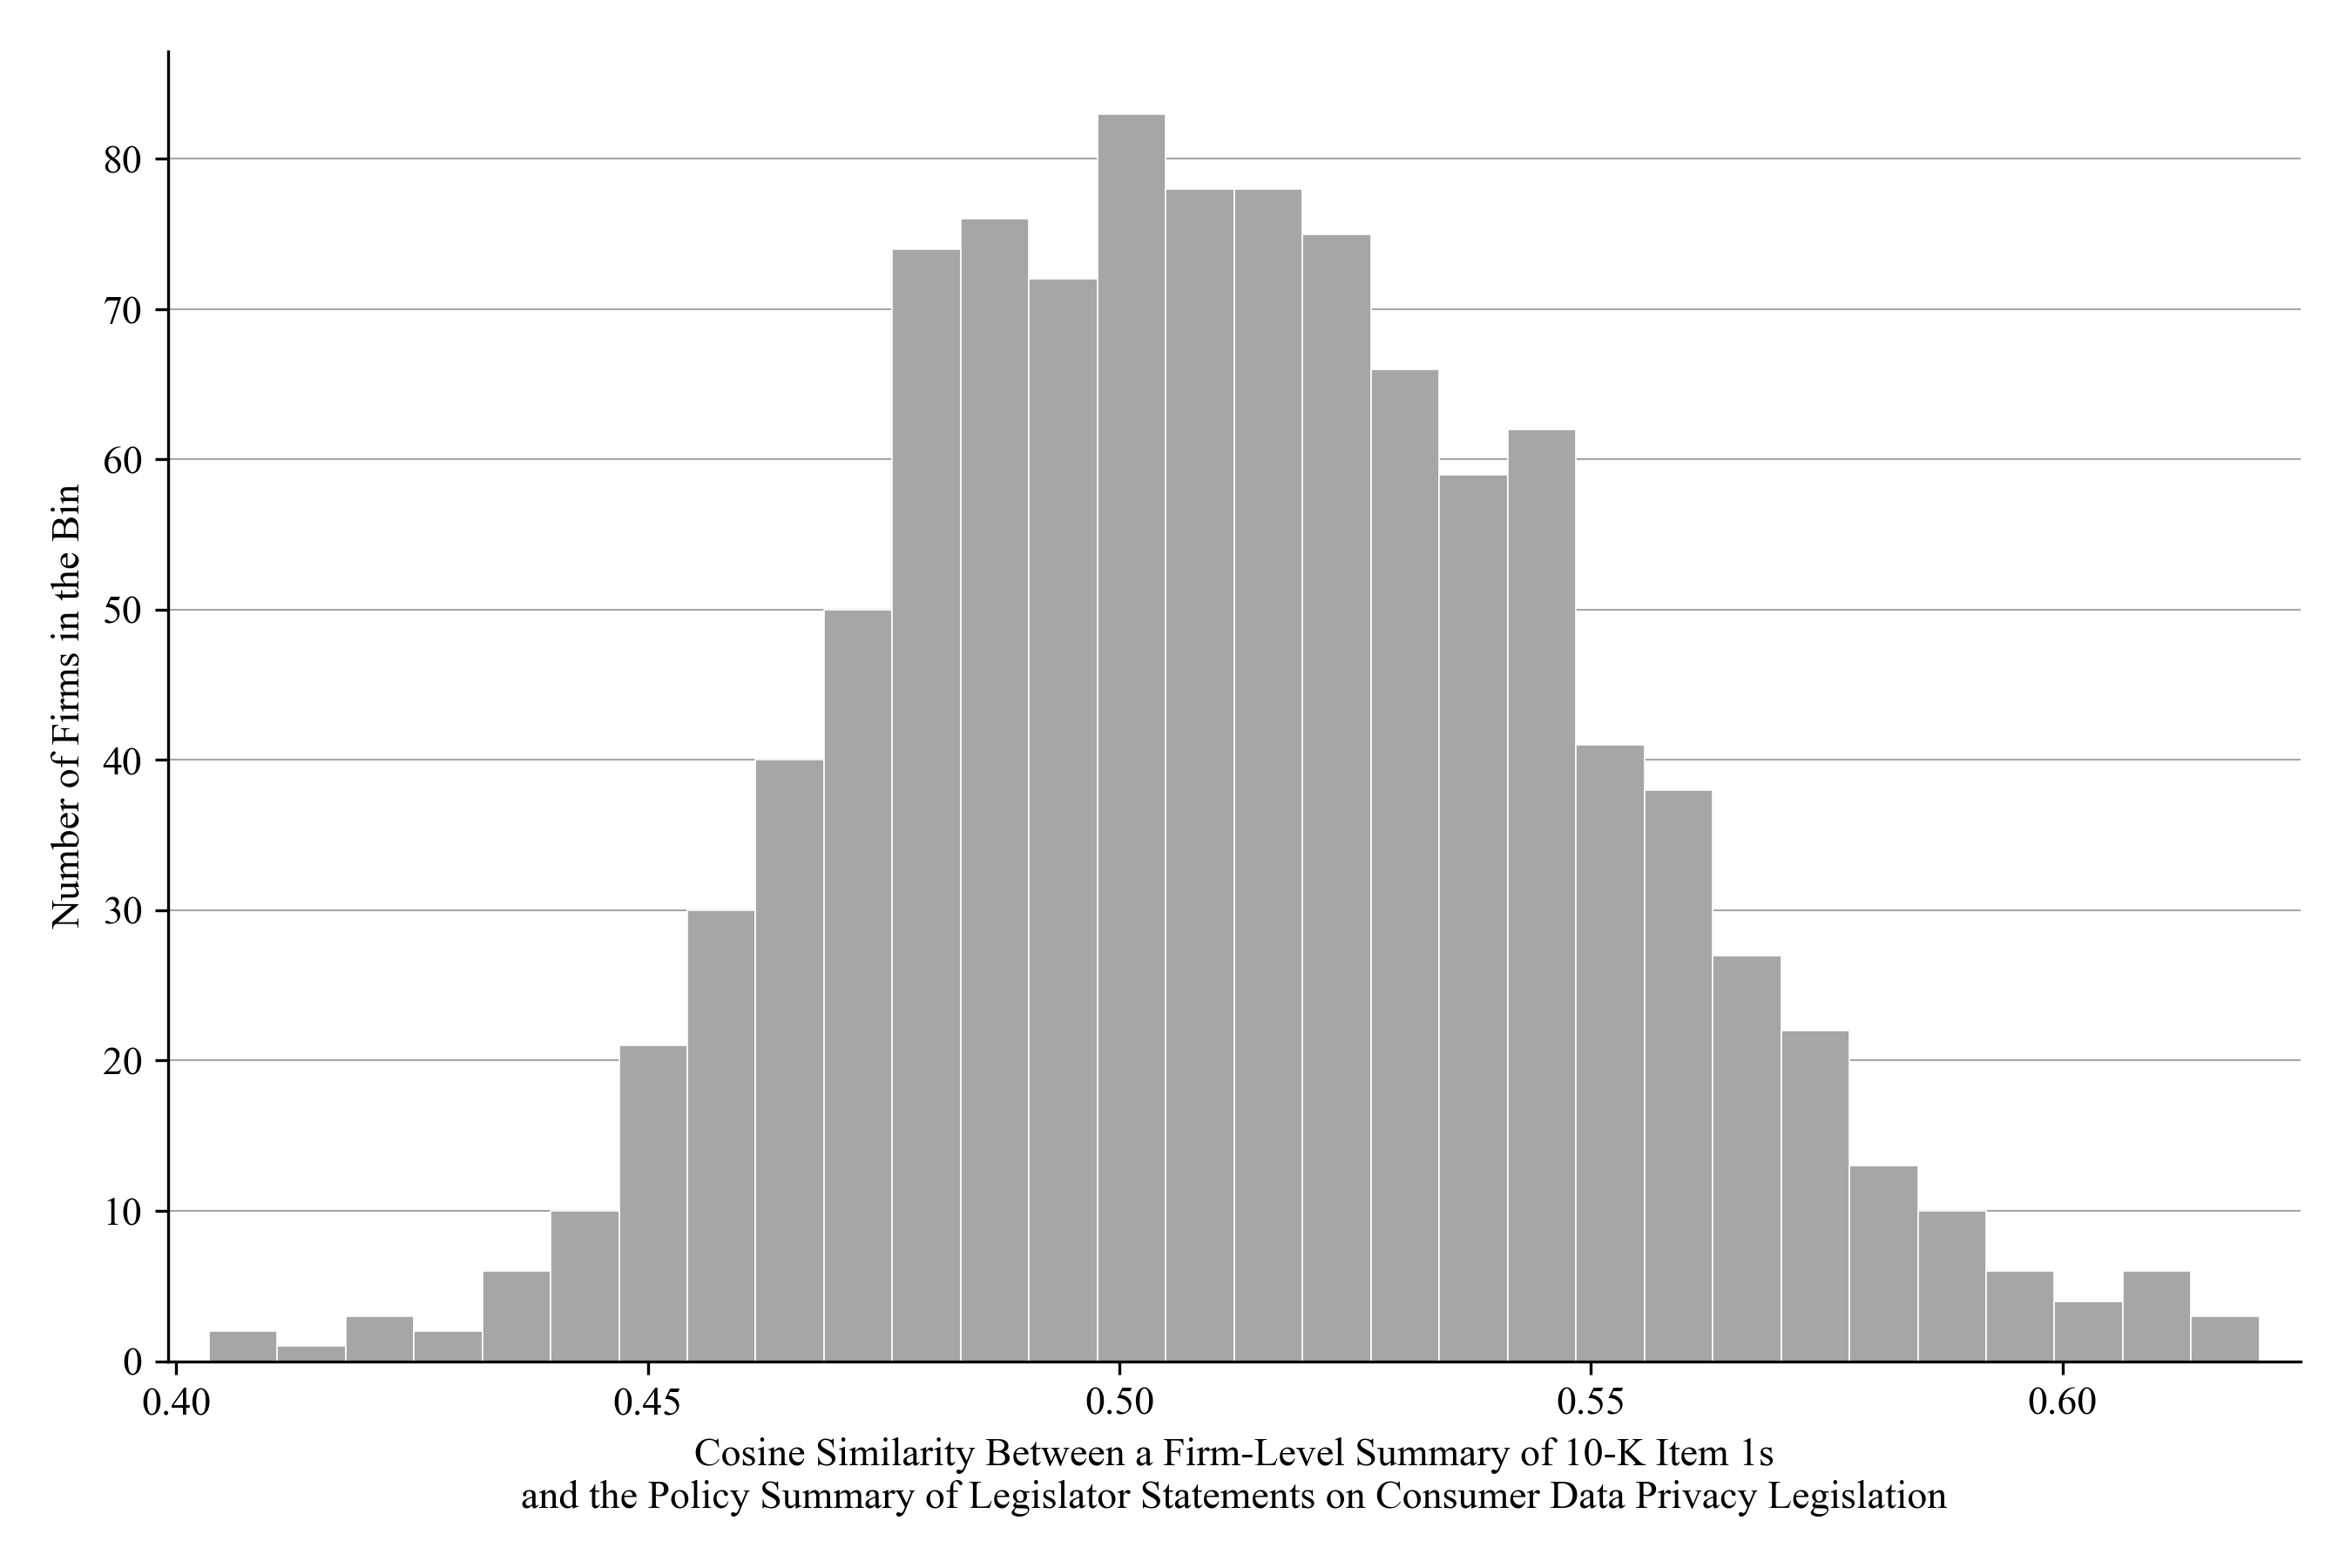

*Notes*: Each bar counts the firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 1,058 firms, whose score falls in the bin; 30 bins of equal width from 0.403 to 0.621, the range of the sample. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. The median is 0.511 and the quartiles are 0.486 and 0.537.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 2. Kernel Density of Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation for Firms in the Information, Manufacturing, and Mining Sectors**

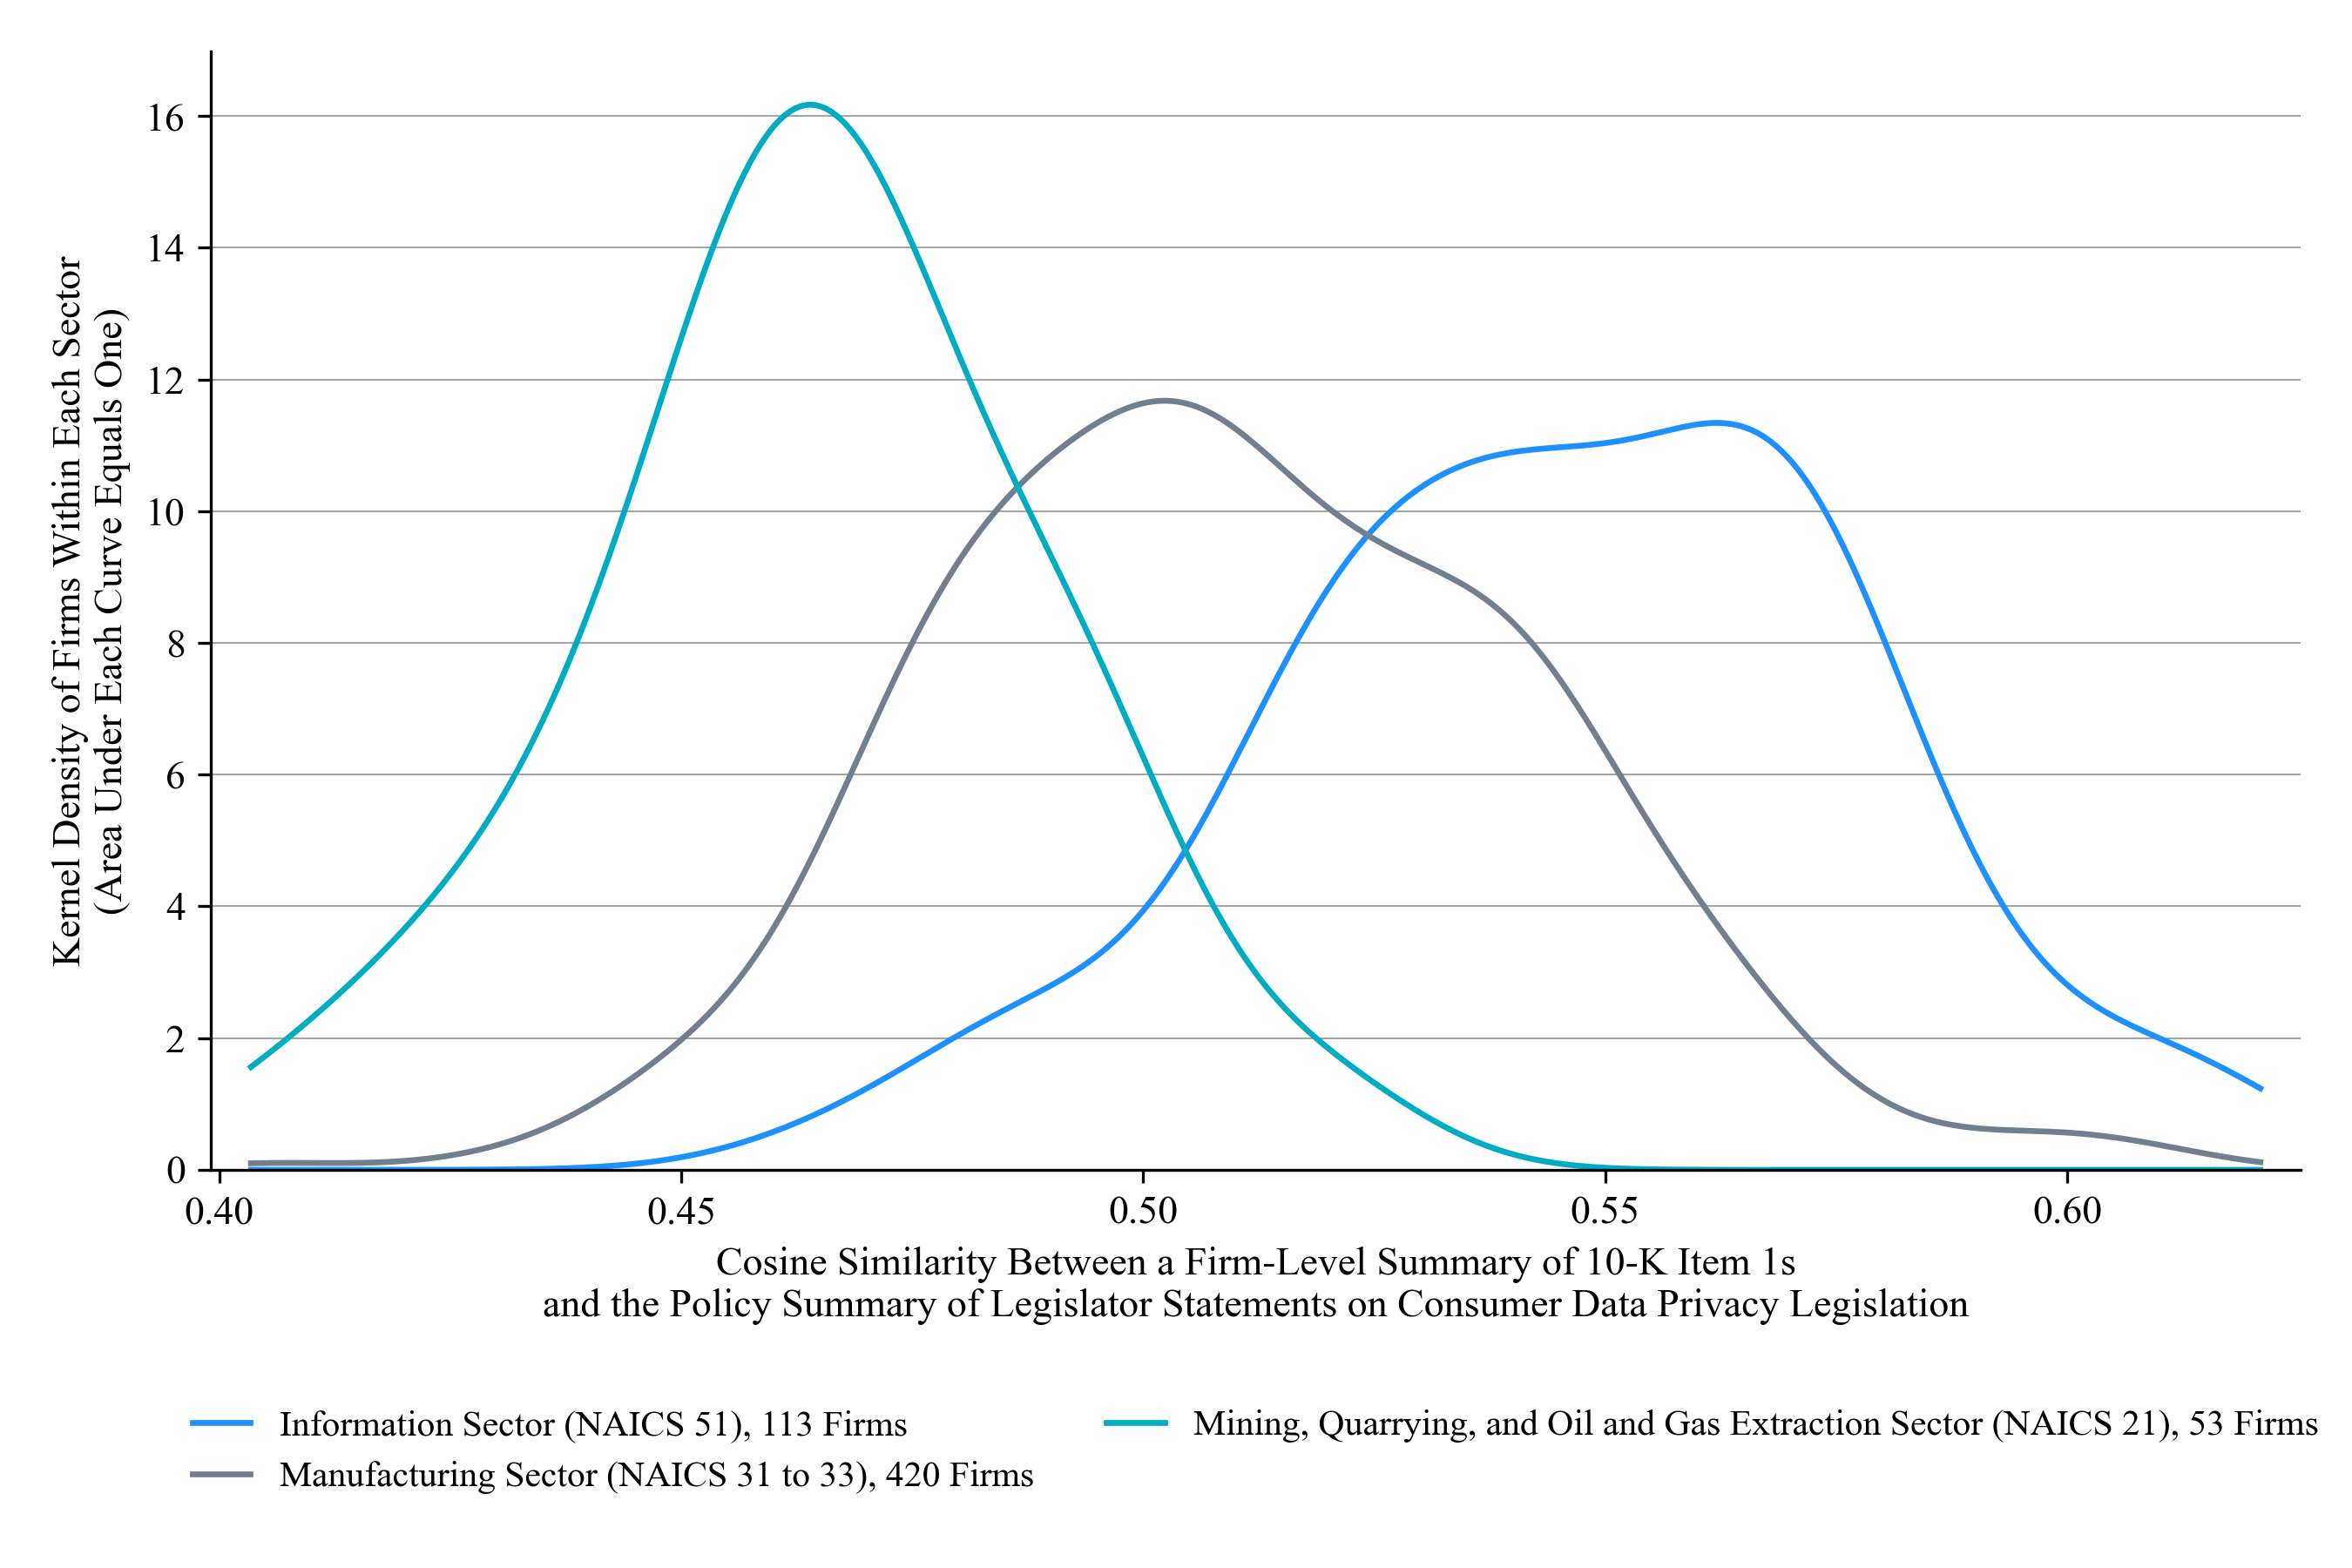

*Notes*: Each line is a Gaussian kernel density estimate with Scott's bandwidth of the scores of the firms in one sector, evaluated from 0.403 to 0.621, the range of the sample. The height of a line at a score is the density of the sector's firms at that score, not a count: the area under each line equals one, so sectors with different numbers of firms are comparable, and a line further to the right means that the sector's firms score higher. Firms are those of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 1,058 firms, and the sector is the firm's Compustat NAICS code cut to two digits, with codes 31 to 33 merged into manufacturing. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. Sectors shown: Information Sector (NAICS 51), 113 firms, median 0.546; Manufacturing Sector (NAICS 31 to 33), 420 firms, median 0.508; Mining, Quarrying, and Oil and Gas Extraction Sector (NAICS 21), 53 firms, median 0.465.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [7]:
show_figure(1, FIGURE_TITLES[1], FIGURE_NAMES[1], notes_1, SOURCE)
show_figure(2, FIGURE_TITLES[2], FIGURE_NAMES[2], notes_2, SOURCE)
